In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pathlib
import os
import glob as gb
import cv2
import PIL
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping ,ReduceLROnPlateau 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D , Dense , Dropout , Flatten , MaxPooling2D , BatchNormalization
from tensorflow.keras.utils import to_categorical
from keras.applications.vgg16 import VGG16
from keras.applications.vgg19 import VGG19
from tensorflow import keras
from keras.models import Model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical

In [4]:
#data path
trainpath = r'C:\Users\Acer\Documents\Computer Vision Lab\Lab-7\Skin_Cancer\train'#Please give the path where you are saving the train folder.
testpath = r'C:\Users\Acer\Documents\Computer Vision Lab\Lab-7\Skin_Cancer\test'#please give the path where you are saving the test folder.

In [5]:
# Train Images
new_size=224
train_images=[]
train_labels=[]
for i in os.listdir(trainpath):
  print("Entering to the folder name:",i)
  files=gb.glob(pathname=str(trainpath+'/' + i + '/*.jpg'))
  print("Number of images in the folder is",len(files))
  for j in files:
      class_cancer={'benign':0,'malignant':1}
      image_raw=cv2.imread(j)
      image=cv2.cvtColor(image_raw,cv2.COLOR_BGR2RGB)
      resize_image=cv2.resize(image,(new_size,new_size))
      train_images.append(list(resize_image))
      train_labels.append(class_cancer[i])

Entering to the folder name: benign
Number of images in the folder is 25
Entering to the folder name: malignant
Number of images in the folder is 25


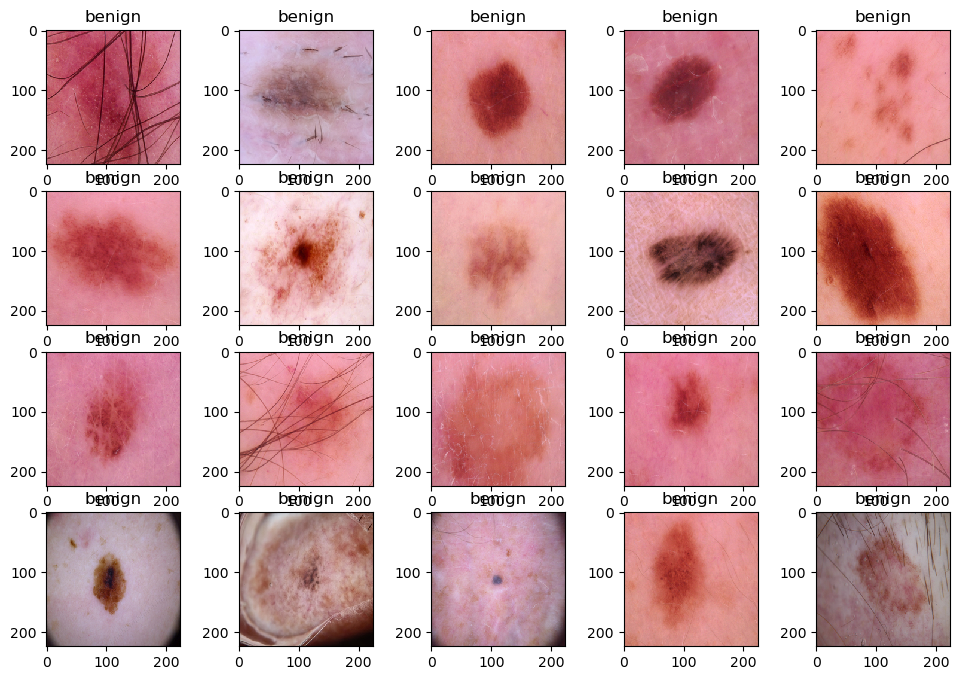

(50, 224, 224, 3)
********************
(50,)
********************


In [6]:
# Visualizing Train Images
w=40
h=30
fig=plt.figure(figsize=(12, 8))
columns = 5
rows = 4

for i in range(1, columns*rows +1):
    ax = fig.add_subplot(rows, columns, i)
    if train_labels[i] == 0:
        ax.title.set_text('benign')
    elif train_labels[i] == 1:
        ax.title.set_text('malignant')
    plt.imshow(train_images[i], interpolation='nearest')
plt.show()

def list_to_array_train(train_images,train_labels):
  return np.array(train_images),np.array(train_labels)

X_train,y_train=list_to_array_train(train_images,train_labels)
print(X_train.shape)
print("*"*20)
print(y_train.shape)
print("*"*20)

In [7]:
# Test Images
new_size=224
test_images=[]
test_labels=[]
for i in os.listdir(testpath):# entering to the test folder
  print("Entering to the folder name:",i)
  files=gb.glob(pathname=str(testpath +'/' + i + '/*.jpg'))# pointing to all the .jpg extension image folder
  print("Number of images in the folder is",len(files))
  class_cancer={'benign':0,'malignant':1}
  for j in files:
      image_raw=cv2.imread(j)
      image=cv2.cvtColor(image_raw,cv2.COLOR_BGR2RGB)
      resize_image=cv2.resize(image,(new_size,new_size))
      test_images.append(list(resize_image))
      test_labels.append(class_cancer[i])

def list_to_array_test(test_images,test_labels):
  return np.array(test_images),np.array(test_labels)

X_test,y_test=list_to_array_test(test_images,test_labels)
print(X_test.shape)
print(y_test.shape)

Entering to the folder name: benign
Number of images in the folder is 25
Entering to the folder name: malignant
Number of images in the folder is 25
(50, 224, 224, 3)
(50,)


In [8]:
def keras_to_categorical(y_train,y_test):
  return to_categorical(y_train),to_categorical(y_test)

y_train,y_test=keras_to_categorical(y_train,y_test)
y_train.shape,y_test.shape

#Use a pretrained VGG-16 model on Imagenet dataset by removing the top fully 
#connected layers and adding three dense layers having 64, 32 and 2 neurons with 
#relu, sigmoid and softmax activation functions respectively for classifying the two 
#class Skin_Cancer RGB dataset

def model_vgg16():
  VGG_model = VGG16(weights='imagenet', include_top=False, input_shape=(224,224, 3))
  #Make loaded layers as non-trainable. This is important as we want to work with pre-trained weights
  for layer in VGG_model.layers:
    layer.trainable = False #True for actual transfer learning
  feature=keras.layers.GlobalAveragePooling2D()(VGG_model.output)
  d1=Dense(units=64,kernel_initializer="glorot_uniform", activation='relu')(feature)
  d2=Dense(units=32,kernel_initializer="glorot_uniform", activation='sigmoid')(d1)
  d3=Dense(units=2,kernel_initializer="glorot_uniform", activation='softmax')(d2)
  output = Model(inputs =VGG_model.input, outputs =d3)
  
  return output

model16=model_vgg16()
model16.compile(optimizer='Adam', loss='categorical_crossentropy', metrics=['accuracy'],run_eagerly=True)
history = model16.fit(X_train, y_train, validation_split=0.2,epochs= 10, batch_size= 1, verbose=1,validation_data=(X_test,y_test))

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 107s 2s/step - accuracy: 0.6887 - loss: 0.6562 - val_accuracy: 0.8000 - val_loss: 0.4440
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 108s 2s/step - accuracy: 0.9641 - loss: 0.3083 - val_accuracy: 0.8600 - val_loss: 0.3284
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 107s 2s/step - accuracy: 0.9838 - loss: 0.2058 - val_accuracy: 0.8400 - val_loss: 0.2829
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 103s 2s/step - accuracy: 1.0000 - loss: 0.1025 - val_accuracy: 0.7800 - val_loss: 0.4812
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 178s 3s/step - accuracy: 1.0000 - loss: 0.0677 - val_accuracy: 0.8200 - val_loss: 0.4210
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 104s 2s/step - accuracy: 1.0000 - loss: 0.0398 - val_accuracy: 0.8200 - val_loss: 0.4019
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 99s 2s/step - accuracy: 1.0000 - loss: 0.0277 - val_accuracy: 0.8200 - val_loss: 0.4106
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 100s 2s/step - accuracy: 1.0000 - loss: 0.0238 - val_accuracy: 0.8200 - va

2/2 ━━━━━━━━━━━━━━━━━━━━ 14s 5s/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 11s 4s/step
Train Accuracy Score: 1.0
Test Accuracy Score: 0.82


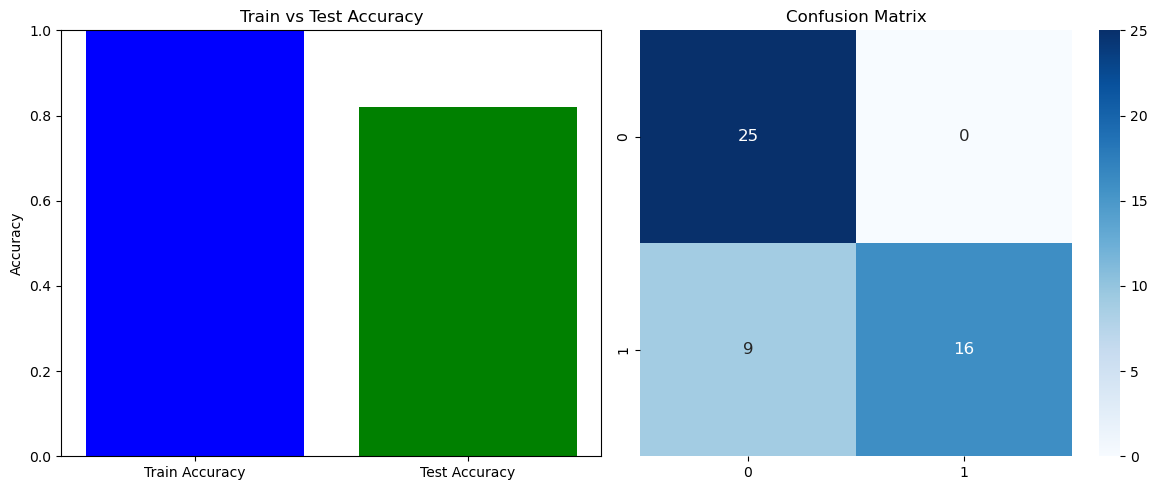

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import pickle

model16.compile(optimizer='Adam', loss='categorical_crossentropy', metrics=['accuracy'],run_eagerly=True)
pickle.dump(model16, open('model16.pkl','wb'))
train_feature_16=model16.predict(X_train)
test_feature_16=model16.predict(X_test)

# Train the RandomForest model
rf = RandomForestClassifier(random_state=42)
rf.fit(train_feature_16, y_train)

# Make predictions
train_pred = rf.predict(train_feature_16)
test_pred = rf.predict(test_feature_16)

# Calculate accuracy
train_acc = accuracy_score(y_train, train_pred)
test_acc = accuracy_score(y_test, test_pred)

print("Train Accuracy Score:", train_acc)
print("Test Accuracy Score:", test_acc)

# Create a figure for accuracy plot and confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot accuracy as a bar chart
axes[0].bar(["Train Accuracy", "Test Accuracy"], [train_acc, test_acc], color=['blue', 'green'])
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Train vs Test Accuracy")

# Plot confusion matrix
cm = confusion_matrix(y_test.argmax(axis=1), test_pred.argmax(axis=1))
sns.heatmap(cm, cmap="Blues", cbar=True, annot=True, annot_kws={"size": 12}, ax=axes[1])
axes[1].set_title("Confusion Matrix")

# Show the plots
plt.tight_layout()
plt.show()